# 🏦 Consumer Complaint Classification

An end-to-end NLP project that automatically routes a customer's written complaint to the correct product category. It compares:

- **SimpleRNN**, **LSTM** and **GRU** networks built from scratch with Keras
- A **fine-tuned Transformer** (DistilBERT via HuggingFace)
- A **TF-IDF + Logistic Regression** baseline

The best model is deployed as an interactive **Gradio** web app that returns the predicted category and a confidence score.


## Notebook outline
1. Install libraries
2. Load and explore the data
3. Text preprocessing
4. Class imbalance handling
5. Label encoding and train / validation / test split
6. Tokenization and padding
7. Build the SimpleRNN / LSTM / GRU models
8. Train the three models
9. Fine-tune the Transformer (DistilBERT)
10. Evaluate and compare all models (baseline, final comparison, error analysis)
11. Classify new complaints
12. Deploy with Gradio

> **Methodological notes**
> - Undersampling is applied **before** the train / validation / test split, so the test set is more balanced than the real complaint distribution.
> - SimpleRNN / LSTM / GRU use **undersampling + class weights**; DistilBERT uses **undersampling only**; the TF-IDF baseline uses `class_weight="balanced"`.
> - Because of this, **Macro F1** is the primary comparison metric, not accuracy.
> - The tokenizer and the TF-IDF vectorizer are fit on the training split only (no data leakage).

## 1️⃣ Install libraries

In [6]:
# Kaggle and Colab ship with TensorFlow, PyTorch and Transformers, so only the missing packages are installed.
# (On Kaggle: Settings -> Internet must be On for pip and for downloading DistilBERT.)
!pip install -q gradio datasets accelerate

!pip install -q tensorflow scikit-learn pandas numpy nltk matplotlib seaborn \
    transformers datasets accelerate torch gradio imbalanced-learn joblib

import nltk
nltk.download('stopwords', quiet=True)
nltk.download('wordnet', quiet=True)
nltk.download('omw-1.4', quiet=True)
print("✅ Libraries installed")

✅ Libraries installed


## 2️⃣ Load and explore the data



In [7]:
import random
import pandas as pd
from pathlib import Path

random.seed(42)

CATEGORIES = {
    "Credit card": [
        "I was charged twice for the same purchase on my credit card statement and the bank refuses to refund me.",
        "My credit card was closed without any notice and it hurt my credit score badly.",
        "There is a fraudulent charge on my credit card that I never authorized.",
        "The interest rate on my credit card increased suddenly without any explanation.",
        "I have been trying to dispute a credit card charge for three months with no resolution.",
        "My credit card application was denied but I was never told the reason.",
        "I keep getting billed for an annual fee I was told would be waived.",
        "The credit card company reported a late payment that I actually paid on time.",
    ],
    "Mortgage": [
        "My mortgage servicer keeps sending incorrect statements about my escrow account.",
        "I applied for a loan modification on my mortgage and never received a response.",
        "The bank started foreclosure proceedings even though I was making payments.",
        "My mortgage payment increased without any prior notice or explanation.",
        "I was told my mortgage was transferred to a new servicer but nobody informed me properly.",
        "The mortgage company is charging me late fees despite receiving my payment on time.",
        "I cannot get clear information about my mortgage refinance application status.",
        "My escrow account for property taxes was mismanaged by the mortgage company.",
    ],
    "Debt collection": [
        "A debt collector keeps calling me multiple times a day about a debt that is not mine.",
        "I am being harassed by a collection agency for a debt I already paid off.",
        "The debt collector threatened legal action even though the debt is past the statute of limitations.",
        "I never received any written validation notice for this alleged debt.",
        "A collection agency reported an inaccurate debt to the credit bureaus.",
        "I asked the debt collector to stop contacting me but they continue calling my workplace.",
        "The collector is trying to collect a debt that was already discharged in bankruptcy.",
        "I am receiving collection calls for a debt that resulted from identity theft.",
    ],
    "Student loan": [
        "My student loan servicer misapplied my payments causing my balance to increase.",
        "I was denied income driven repayment even though I qualify based on my income.",
        "The student loan company will not respond to my requests for a payment plan.",
        "My loan forgiveness application has been pending for over a year with no update.",
        "I am being charged interest on my student loan during a period it should have been paused.",
        "The servicer transferred my student loan without notifying me and I missed a payment.",
        "My credit report shows late payments on a student loan that was in deferment.",
        "I cannot get accurate information about my student loan payoff amount.",
    ],
    "Bank account or service": [
        "My bank closed my checking account without any warning or explanation.",
        "I was charged an overdraft fee even though I had sufficient funds in my account.",
        "The bank froze my account for weeks and would not tell me why.",
        "There was an unauthorized withdrawal from my savings account.",
        "My direct deposit was delayed for several days causing me to miss bill payments.",
        "The bank refuses to reimburse me for a wire transfer error on their part.",
        "I was charged monthly maintenance fees despite meeting the minimum balance requirement.",
        "My debit card was compromised and the bank denied my fraud claim.",
    ],
    "Money transfer or virtual currency": [
        "My money transfer never arrived at the recipient and the company will not refund me.",
        "I was scammed through a payment app and the company refused to investigate.",
        "The virtual currency exchange froze my account with all my funds inside.",
        "My international wire transfer disappeared and support is unresponsive.",
        "I sent money to the wrong account due to a system error and cannot get it back.",
        "The payment app charged hidden fees that were never disclosed to me.",
        "My transaction is stuck pending for over two weeks with no explanation.",
        "I could not withdraw my funds from the money transfer platform.",
    ],
}

def make_variant(text):
    fillers = ["", " This has caused me significant stress.", " I have contacted customer service multiple times.",
        " Please help me resolve this issue as soon as possible.", " I have all documentation available.",
        " This is unacceptable and needs to be fixed immediately."]
    return text + random.choice(fillers)

def build_dataframe(n_per_class=150):
    rows = []
    for product, examples in CATEGORIES.items():
        for _ in range(n_per_class):
            base = random.choice(examples)
            rows.append({"Consumer complaint narrative": make_variant(base), "Product": product})
    return pd.DataFrame(rows).sample(frac=1, random_state=42).reset_index(drop=True)

USE_SAMPLE_DATA = False   # True = synthetic data for a quick smoke test only (never use it for reported results)
DATA_PATH ='/kaggle/input/datasets/shashwatwork/consume-complaints-dataset-fo-nlp/complaints_processed.csv'         # None = auto-search /kaggle/input, /content and data/; or set the path yourself
SAMPLE_SIZE = None    # number of complaints to use (None = all); the full dataset is huge and slows training a lot

import glob, os
Path("data").mkdir(exist_ok=True)

if USE_SAMPLE_DATA:
    DATA_PATH = "data/complaints.csv"
    build_dataframe(150).to_csv(DATA_PATH, index=False)
    print("⚠️ Using SYNTHETIC data - the metrics are not real and must not be reported")
elif DATA_PATH is None:
    found = [p for root in ("/kaggle/input", "/content", "data")
             for p in glob.glob(f"{root}/**/*.csv", recursive=True)
             if "complaint" in os.path.basename(p).lower()]
    if not found:
        raise FileNotFoundError(
            "Dataset file not found. On Kaggle: click Add Input and add the dataset, "
            "or set DATA_PATH yourself. CSV files found under /kaggle/input:\n"
            + "\n".join(glob.glob("/kaggle/input/**/*.csv", recursive=True)[:20]))
    DATA_PATH = max(found, key=os.path.getsize)   # if several files match, take the largest one
    print("📂 Using dataset file:", DATA_PATH)
    if len(found) > 1:
        print("   (multiple matching files found:", found, ")")

# Column names differ between dataset versions on Kaggle
# (e.g. Consumer complaint narrative / consumer_complaint_narrative / narrative, and Product / product)
TEXT_ALIASES = ["consumer complaint narrative", "narrative", "complaint what happened", "complaint text", "text"]
LABEL_ALIASES = ["product", "label", "category"]
_norm = lambda x: str(x).lower().replace("_", " ").strip()
header = pd.read_csv(DATA_PATH, nrows=0).columns.tolist()

def _pick(aliases):
    for alias in aliases:
        for c in header:
            if _norm(c) == alias:
                return c
    return None

text_col, label_col = _pick(TEXT_ALIASES), _pick(LABEL_ALIASES)
if text_col is None or label_col is None:
    raise KeyError(f"Could not detect the text/label columns automatically. Columns in the file: {header}\n"
                   "Set text_col and label_col manually.")
col_map = {text_col: "text", label_col: "label"}
print(f"🧾 Text column: '{text_col}' | Label column: '{label_col}'")

# usecols: read only the two needed columns to save memory (the full CFPB file exceeds 1 GB)
df = pd.read_csv(DATA_PATH, usecols=list(col_map), low_memory=False).rename(columns=col_map).dropna()
if SAMPLE_SIZE and len(df) > SAMPLE_SIZE:
    df = df.sample(SAMPLE_SIZE, random_state=42).reset_index(drop=True)
print(f"Total rows used: {len(df)}")
df.head()

🧾 Text column: 'narrative' | Label column: 'product'
Total rows used: 162411


,label,text
0,credit_card,purchase order day shipping amount receive pro...
1,credit_card,forwarded message date tue subject please inve...
2,retail_banking,forwarded message cc sent friday pdt subject f...
3,credit_reporting,payment history missing credit report speciali...
4,credit_reporting,payment history missing credit report made mis...


📊 Class distribution:
label
credit_reporting       91172
debt_collection        23148
mortgages_and_loans    18990
credit_card            15566
retail_banking         13535
Name: count, dtype: int64


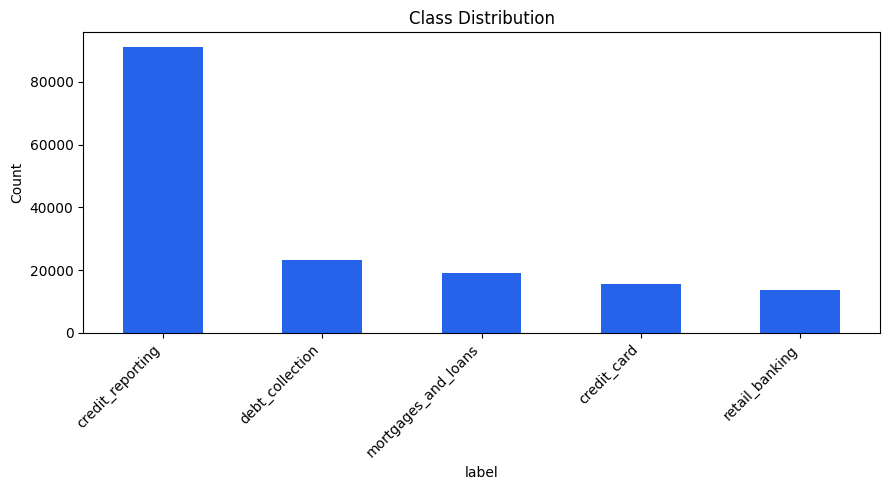

In [8]:
# Explore the class distribution
import matplotlib.pyplot as plt

TOP_N_CLASSES = 10
top_classes = df["label"].value_counts().nlargest(TOP_N_CLASSES).index
df = df[df["label"].isin(top_classes)].reset_index(drop=True)

print("📊 Class distribution:")
print(df["label"].value_counts())

plt.figure(figsize=(9, 5))
df["label"].value_counts().plot(kind="bar", color="#2563eb")
plt.title("Class Distribution")
plt.ylabel("Count")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

## 3️⃣ Text preprocessing

In [9]:
import re
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

STOPWORDS = set(stopwords.words("english"))
LEMMATIZER = WordNetLemmatizer()

def clean_text(text):
    if not isinstance(text, str):
        return ""
    text = text.lower()
    text = re.sub(r"x{2,}", " ", text)              # CFPB redacted placeholders "XXXX"
    text = re.sub(r"http\S+|www\S+", " ", text)
    text = re.sub(r"[^a-z\s]", " ", text)            # remove numbers/punctuation/special chars
    text = re.sub(r"\s+", " ", text).strip()
    tokens = [t for t in text.split() if t not in STOPWORDS and len(t) > 1]
    tokens = [LEMMATIZER.lemmatize(t) for t in tokens]
    return " ".join(tokens)

df["clean_text"] = df["text"].apply(clean_text)
df["word_count"] = df["clean_text"].apply(lambda x: len(x.split()))
df = df[df["word_count"] >= 3].reset_index(drop=True)

print("Before:", df["text"].iloc[0])
print("After :", df["clean_text"].iloc[0])
df[["text", "clean_text"]].head()

Before: purchase order day shipping amount receive product week sent followup email exact verbiage paid two day shipping received order company responded im sorry inform due unusually high order volume order shipped several week stock since early due high demand although continuing take order guaranteeing receive order place due time mask order exact shipping date right however guarantee ship soon soon delivers product u getting small shipment shipping first come first served basis appreciate patience fulfill order quickly recommend keeping order lose place line cancel distributor stock moment prefer cancel please note ask via email cancel accordance cancellation policy agreed checkout electronic inventory online requested order canceled refund issued canceled order sent verification order canceled refunded item particulate respirator refunded subtotal shipping tax total usd visa ending refund called disputed amount stated nothing needed submitted address issue recharged item removing 

,text,clean_text
0,purchase order day shipping amount receive pro...,purchase order day shipping amount receive pro...
1,forwarded message date tue subject please inve...,forwarded message date tue subject please inve...
2,forwarded message cc sent friday pdt subject f...,forwarded message cc sent friday pdt subject f...
3,payment history missing credit report speciali...,payment history missing credit report speciali...
4,payment history missing credit report made mis...,payment history missing credit report made mis...


## 4️⃣ Class imbalance handling

Majority classes are undersampled to at most 3× the size of the smallest class.

> **Methodology notes**
> - Undersampling happens **before** the split, so the test set is more balanced than the real-world complaint distribution.
> - SimpleRNN / LSTM / GRU combine **undersampling + class weights**; DistilBERT uses **undersampling only**.
> - Therefore **Macro F1** is the primary comparison metric, not accuracy.

In [10]:
RANDOM_STATE = 42

def handle_class_imbalance(df, max_ratio=3.0):
    counts = df["label"].value_counts()
    min_count = counts.min()
    cap = int(min_count * max_ratio)
    parts = []
    for label, group in df.groupby("label"):
        if len(group) > cap:
            group = group.sample(cap, random_state=RANDOM_STATE)
        parts.append(group)
    return pd.concat(parts).sample(frac=1, random_state=RANDOM_STATE).reset_index(drop=True)

df_balanced = handle_class_imbalance(df)
print(f"Before: {len(df)} rows -> After balancing: {len(df_balanced)} rows")
df_balanced["label"].value_counts()

Before: 162016 rows -> After balancing: 111670 rows


label
credit_reporting       40533
debt_collection        23078
mortgages_and_loans    18985
credit_card            15563
retail_banking         13511
Name: count, dtype: int64

## 5️⃣ Label Encoding + Train/Val/Test Split

In [11]:
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split

le = LabelEncoder()
df_balanced["label_id"] = le.fit_transform(df_balanced["label"])
num_classes = len(le.classes_)
print(f"Classes ({num_classes}): {list(le.classes_)}")

X_temp, X_test, y_temp, y_test = train_test_split(
    df_balanced["clean_text"].values, df_balanced["label_id"].values,
    test_size=0.15, random_state=RANDOM_STATE, stratify=df_balanced["label_id"].values
)
X_train, X_val, y_train, y_val = train_test_split(
    X_temp, y_temp, test_size=0.15, random_state=RANDOM_STATE, stratify=y_temp
)
print(f"Train: {len(X_train)} | Val: {len(X_val)} | Test: {len(X_test)}")

Classes (5): ['credit_card', 'credit_reporting', 'debt_collection', 'mortgages_and_loans', 'retail_banking']
Train: 80681 | Val: 14238 | Test: 16751


## 6️⃣ Tokenization + Padding

In [12]:
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

MAX_VOCAB_SIZE = 20000
MAX_SEQ_LEN = 150

tokenizer = Tokenizer(num_words=MAX_VOCAB_SIZE, oov_token="<OOV>")
tokenizer.fit_on_texts(X_train)

def to_padded(texts):
    seqs = tokenizer.texts_to_sequences(texts)
    return pad_sequences(seqs, maxlen=MAX_SEQ_LEN, padding="post", truncating="post")

X_train_pad = to_padded(X_train)
X_val_pad = to_padded(X_val)
X_test_pad = to_padded(X_test)

vocab_size = min(MAX_VOCAB_SIZE, len(tokenizer.word_index)) + 1
print(f"Vocabulary size: {len(tokenizer.word_index)} | Padded shape: {X_train_pad.shape}")

from sklearn.utils.class_weight import compute_class_weight
import numpy as np
classes_arr = np.unique(y_train)
weights = compute_class_weight(class_weight="balanced", classes=classes_arr, y=y_train)
class_weight_dict = {int(c): float(w) for c, w in zip(classes_arr, weights)}
print("Class weights:", class_weight_dict)

I0000 00:00:1794424483.347960    3985 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


Vocabulary size: 36683 | Padded shape: (80681, 150)
Class weights: {0: 1.4349666518452646, 1: 0.551005634283763, 2: 0.9677461916756627, 3: 1.176450860309128, 4: 1.6531298022743572}


## 7️⃣ Build the models: SimpleRNN / LSTM / GRU

⚠️ **Why `mask_zero=True` matters:** short complaints are post-padded to a fixed length (150). Without masking, the recurrent layers (especially LSTM and GRU) keep processing dozens of padding steps after the real text, which washes out the useful signal and leaves the model stuck at chance-level accuracy.

In [13]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Input, Embedding, SimpleRNN, LSTM, GRU, Dense, Dropout,
    Bidirectional, SpatialDropout1D
)
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.regularizers import l2

EMBEDDING_DIM = 128

def build_simple_rnn(vocab_size, max_len, num_classes):
    model = Sequential(name="SimpleRNN_Model")
    model.add(Input(shape=(max_len,)))   # explicit input -> summary() shows shapes before training
    model.add(Embedding(input_dim=vocab_size, output_dim=EMBEDDING_DIM, mask_zero=True))
    model.add(SpatialDropout1D(0.2))
    model.add(Bidirectional(SimpleRNN(64, return_sequences=True)))
    model.add(SimpleRNN(32))
    model.add(Dropout(0.4))
    model.add(Dense(64, activation="relu", kernel_regularizer=l2(1e-4)))
    model.add(Dropout(0.3))
    model.add(Dense(num_classes, activation="softmax"))
    model.compile(optimizer=Adam(1e-3), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return model

def build_lstm(vocab_size, max_len, num_classes):
    model = Sequential(name="LSTM_Model")
    model.add(Input(shape=(max_len,)))   # explicit input -> summary() shows shapes before training
    model.add(Embedding(input_dim=vocab_size, output_dim=EMBEDDING_DIM, mask_zero=True))
    model.add(SpatialDropout1D(0.2))
    model.add(Bidirectional(LSTM(64, return_sequences=True)))
    model.add(LSTM(32))
    model.add(Dropout(0.4))
    model.add(Dense(64, activation="relu", kernel_regularizer=l2(1e-4)))
    model.add(Dropout(0.3))
    model.add(Dense(num_classes, activation="softmax"))
    model.compile(optimizer=Adam(1e-3), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return model

def build_gru(vocab_size, max_len, num_classes):
    model = Sequential(name="GRU_Model")
    model.add(Input(shape=(max_len,)))   # explicit input -> summary() shows shapes before training
    model.add(Embedding(input_dim=vocab_size, output_dim=EMBEDDING_DIM, mask_zero=True))
    model.add(SpatialDropout1D(0.2))
    model.add(Bidirectional(GRU(64, return_sequences=True)))
    model.add(GRU(32))
    model.add(Dropout(0.4))
    model.add(Dense(64, activation="relu", kernel_regularizer=l2(1e-4)))
    model.add(Dropout(0.3))
    model.add(Dense(num_classes, activation="softmax"))
    model.compile(optimizer=Adam(1e-3), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return model

MODEL_BUILDERS = {"SimpleRNN": build_simple_rnn, "LSTM": build_lstm, "GRU": build_gru}
for _name, _builder in MODEL_BUILDERS.items():
    _builder(vocab_size, MAX_SEQ_LEN, num_classes).summary()

Model: "SimpleRNN_Model"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 150, 128)       │     2,560,128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ spatial_dropout1d               │ (None, 150, 128)       │             0 │
│ (SpatialDropout1D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional (Bidirectional)   │ (None, 150, 128)       │        24,704 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn_1 (SimpleRNN)        │ (None, 32)             │         5,152 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         2,112 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 5)              │           325 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,592,421 (9.89 MB)

 Trainable params: 2,592,421 (9.89 MB)

 Non-trainable params: 0 (0.00 B)

Model: "LSTM_Model"

... (5 outputs left out)

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_2 (Embedding)         │ (None, 150, 128)       │     2,560,128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ spatial_dropout1d_2             │ (None, 150, 128)       │             0 │
│ (SpatialDropout1D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_2 (Bidirectional) │ (None, 150, 128)       │        74,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gru_1 (GRU)                     │ (None, 32)             │        15,552 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 64)             │         2,112 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 5)              │           325 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,652,613 (10.12 MB)

 Trainable params: 2,652,613 (10.12 MB)

 Non-trainable params: 0 (0.00 B)

## 8️⃣ Train the three models

In [14]:
import os, json
os.makedirs("models", exist_ok=True)
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau

EPOCHS = 15
BATCH_SIZE = 64
histories = {}
trained_models = {}

for name, builder in MODEL_BUILDERS.items():
    print("\n" + "="*70, f"\n🚀 Training {name} ...\n" + "="*70)
    model = builder(vocab_size, MAX_SEQ_LEN, num_classes)
    ckpt_path = f"models/{name.lower()}_model.keras"
    callbacks = [
        EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True),
        ModelCheckpoint(ckpt_path, monitor="val_accuracy", save_best_only=True),
        ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2, min_lr=1e-6),
    ]
    history = model.fit(
        X_train_pad, y_train, validation_data=(X_val_pad, y_val),
        epochs=EPOCHS, batch_size=BATCH_SIZE, class_weight=class_weight_dict,
        callbacks=callbacks, verbose=2,
    )
    test_loss, test_acc = model.evaluate(X_test_pad, y_test, verbose=0)
    print(f"✅ {name} — Test Accuracy: {test_acc:.4f}")
    histories[name] = history.history
    trained_models[name] = model


🚀 Training SimpleRNN ...
Epoch 1/15
1261/1261 - 60s - 47ms/step - accuracy: 0.5496 - loss: 1.1050 - val_accuracy: 0.7120 - val_loss: 0.8420 - learning_rate: 0.0010
Epoch 2/15
1261/1261 - 45s - 36ms/step - accuracy: 0.6571 - loss: 0.9856 - val_accuracy: 0.7069 - val_loss: 0.8639 - learning_rate: 0.0010
Epoch 3/15
1261/1261 - 45s - 36ms/step - accuracy: 0.6311 - loss: 1.0006 - val_accuracy: 0.6065 - val_loss: 1.0337 - learning_rate: 0.0010
Epoch 4/15
1261/1261 - 45s - 36ms/step - accuracy: 0.7001 - loss: 0.8726 - val_accuracy: 0.7163 - val_loss: 0.8183 - learning_rate: 5.0000e-04
Epoch 5/15
1261/1261 - 45s - 36ms/step - accuracy: 0.7094 - loss: 0.8609 - val_accuracy: 0.7316 - val_loss: 0.7904 - learning_rate: 5.0000e-04
Epoch 6/15
1261/1261 - 45s - 36ms/step - accuracy: 0.7257 - loss: 0.8191 - val_accuracy: 0.7498 - val_loss: 0.7535 - learning_rate: 5.0000e-04
Epoch 7/15
1261/1261 - 45s - 36ms/step - accuracy: 0.7468 - loss: 0.7837 - val_accuracy: 0.7118 - val_loss: 0.8488 - learning_ra

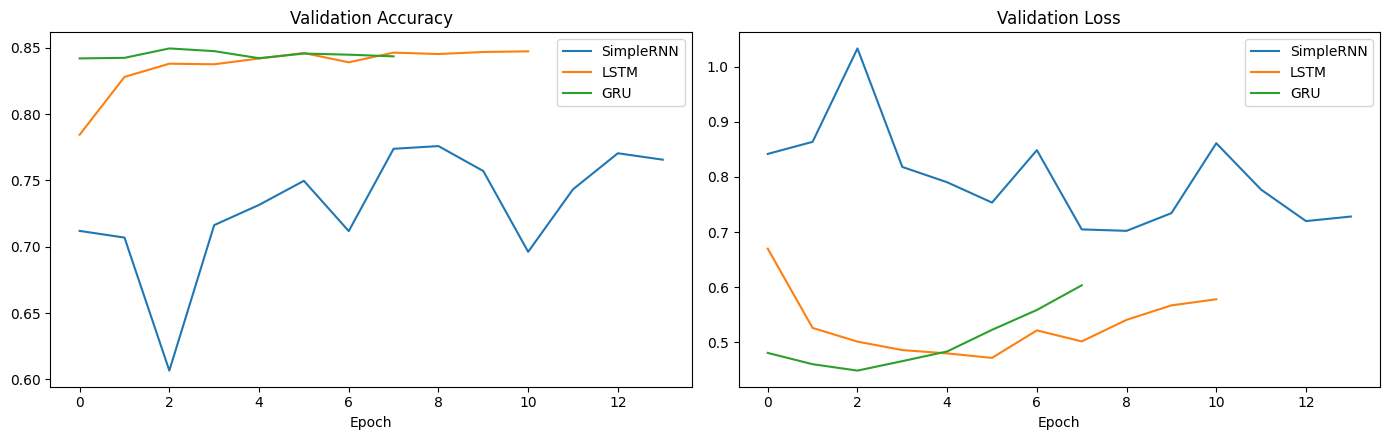

In [15]:
# Plot the training curves
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for name, h in histories.items():
    axes[0].plot(h["val_accuracy"], label=name)
    axes[1].plot(h["val_loss"], label=name)
axes[0].set_title("Validation Accuracy"); axes[0].legend(); axes[0].set_xlabel("Epoch")
axes[1].set_title("Validation Loss"); axes[1].legend(); axes[1].set_xlabel("Epoch")
plt.tight_layout(); plt.show()

## 9️⃣ Fine-tune the Transformer (DistilBERT)


In [16]:
import torch
from sklearn.metrics import accuracy_score, precision_recall_fscore_support
from transformers import (
    AutoTokenizer, AutoModelForSequenceClassification,
    TrainingArguments, Trainer, DataCollatorWithPadding,
)
from datasets import Dataset

MODEL_NAME = "distilbert-base-uncased"
TRANSFORMER_MAX_LEN = 128
TRANSFORMER_EPOCHS = 3
TRANSFORMER_BATCH_SIZE = 16

train_df = pd.DataFrame({"text": X_train, "label": y_train})
val_df = pd.DataFrame({"text": X_val, "label": y_val})
test_df = pd.DataFrame({"text": X_test, "label": y_test})

hf_tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

def tokenize_fn(batch):
    return hf_tokenizer(batch["text"], truncation=True, max_length=TRANSFORMER_MAX_LEN)

train_ds = Dataset.from_pandas(train_df).map(tokenize_fn, batched=True)
val_ds = Dataset.from_pandas(val_df).map(tokenize_fn, batched=True)
test_ds = Dataset.from_pandas(test_df).map(tokenize_fn, batched=True)

data_collator = DataCollatorWithPadding(tokenizer=hf_tokenizer)
transformer_model = AutoModelForSequenceClassification.from_pretrained(MODEL_NAME, num_labels=num_classes)

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    preds = np.argmax(logits, axis=-1)
    acc = accuracy_score(labels, preds)
    precision, recall, f1, _ = precision_recall_fscore_support(labels, preds, average="weighted", zero_division=0)
    return {"accuracy": acc, "precision": precision, "recall": recall, "f1": f1}

training_args = TrainingArguments(
    output_dir="models/transformer_model/checkpoints",
    eval_strategy="epoch", save_strategy="epoch",
    learning_rate=2e-5,
    per_device_train_batch_size=TRANSFORMER_BATCH_SIZE,
    per_device_eval_batch_size=TRANSFORMER_BATCH_SIZE,
    num_train_epochs=TRANSFORMER_EPOCHS, weight_decay=0.01,
    load_best_model_at_end=True, metric_for_best_model="f1",
    logging_steps=50, report_to="none", fp16=torch.cuda.is_available(),
)

import inspect
# Newer transformers versions call this argument processing_class; older ones call it tokenizer
_tok_kw = "processing_class" if "processing_class" in inspect.signature(Trainer.__init__).parameters else "tokenizer"

trainer = Trainer(
    model=transformer_model, args=training_args,
    train_dataset=train_ds, eval_dataset=val_ds,
    data_collator=data_collator, compute_metrics=compute_metrics,
    **{_tok_kw: hf_tokenizer},
)

print("🚀 Fine-tuning DistilBERT ...")
trainer.train()

transformer_test_results = trainer.evaluate(test_ds)
print(transformer_test_results)

trainer.save_model("models/transformer_model")
hf_tokenizer.save_pretrained("models/transformer_model")
print("✅ Transformer saved to models/transformer_model")

Map:   0%|          | 0/80681 [00:00<?, ? examples/s]

Map:   0%|          | 0/14238 [00:00<?, ? examples/s]

Map:   0%|          | 0/16751 [00:00<?, ? examples/s]

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

🚀 Fine-tuning DistilBERT ...


/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


... (9 outputs left out)

/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


{'eval_loss': '0.7967', 'eval_accuracy': '0.8676', 'eval_precision': '0.8678', 'eval_recall': '0.8676', 'eval_f1': '0.8676', 'eval_runtime': '43.76', 'eval_samples_per_second': '382.8', 'eval_steps_per_second': '11.97', 'epoch': '3'}
{'eval_loss': 0.7967131733894348, 'eval_accuracy': 0.8675899946271864, 'eval_precision': 0.8677695649784617, 'eval_recall': 0.8675899946271864, 'eval_f1': 0.8676433399999328, 'eval_runtime': 43.7571, 'eval_samples_per_second': 382.818, 'eval_steps_per_second': 11.975, 'epoch': 3.0}


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

✅ Transformer saved to models/transformer_model


## 🔟 Evaluate and compare the models


=== SimpleRNN ===
                     precision    recall  f1-score   support

        credit_card       0.65      0.79      0.71      2334
   credit_reporting       0.90      0.76      0.82      6080
    debt_collection       0.74      0.76      0.75      3462
mortgages_and_loans       0.75      0.84      0.80      2848
     retail_banking       0.79      0.76      0.77      2027

           accuracy                           0.78     16751
          macro avg       0.76      0.78      0.77     16751
       weighted avg       0.79      0.78      0.78     16751



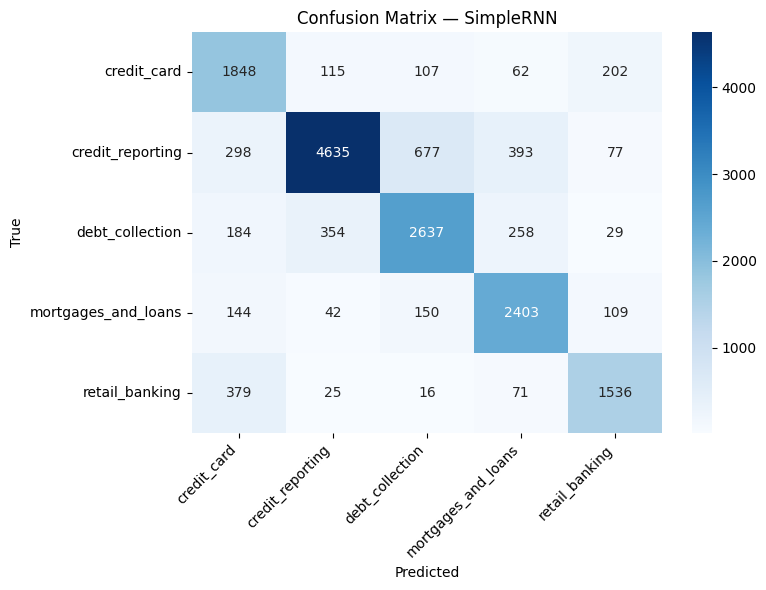


=== LSTM ===
                     precision    recall  f1-score   support

        credit_card       0.73      0.86      0.79      2334
   credit_reporting       0.92      0.83      0.87      6080
    debt_collection       0.83      0.82      0.82      3462
mortgages_and_loans       0.83      0.87      0.85      2848
     retail_banking       0.85      0.88      0.86      2027

           accuracy                           0.85     16751
          macro avg       0.83      0.85      0.84     16751
       weighted avg       0.85      0.85      0.85     16751



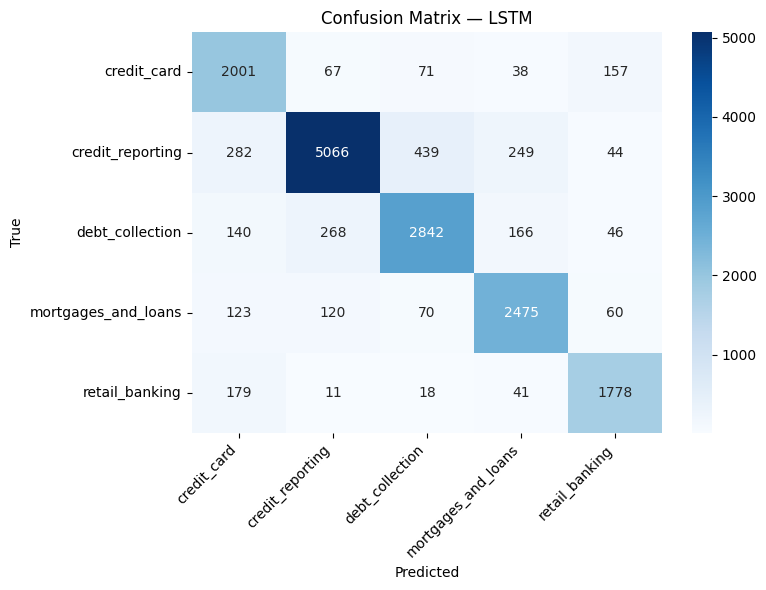


=== GRU ===
                     precision    recall  f1-score   support

        credit_card       0.78      0.82      0.80      2334
   credit_reporting       0.92      0.82      0.87      6080
    debt_collection       0.81      0.83      0.82      3462
mortgages_and_loans       0.83      0.89      0.86      2848
     retail_banking       0.83      0.92      0.87      2027

           accuracy                           0.85     16751
          macro avg       0.83      0.86      0.84     16751
       weighted avg       0.85      0.85      0.85     16751



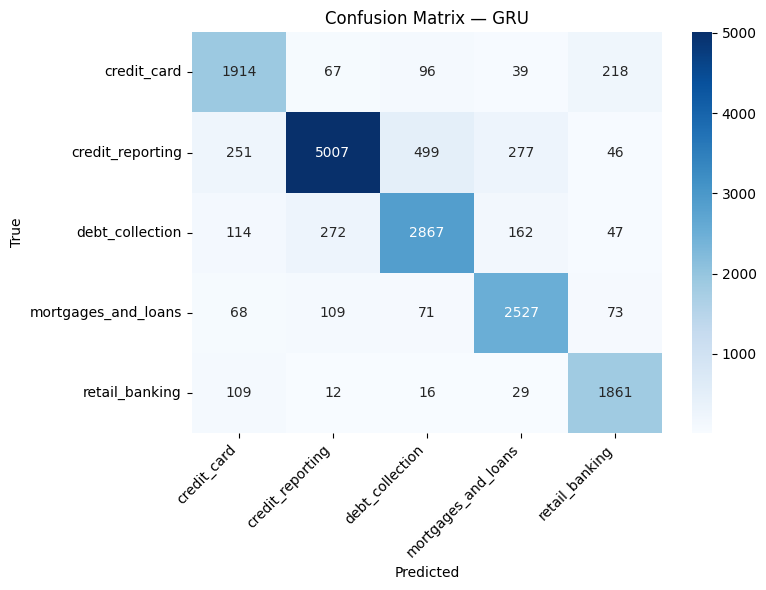


=== Transformer (DistilBERT) ===
                     precision    recall  f1-score   support

        credit_card       0.82      0.84      0.83      2334
   credit_reporting       0.89      0.89      0.89      6080
    debt_collection       0.84      0.83      0.83      3462
mortgages_and_loans       0.88      0.87      0.88      2848
     retail_banking       0.89      0.90      0.89      2027

           accuracy                           0.87     16751
          macro avg       0.86      0.87      0.86     16751
       weighted avg       0.87      0.87      0.87     16751



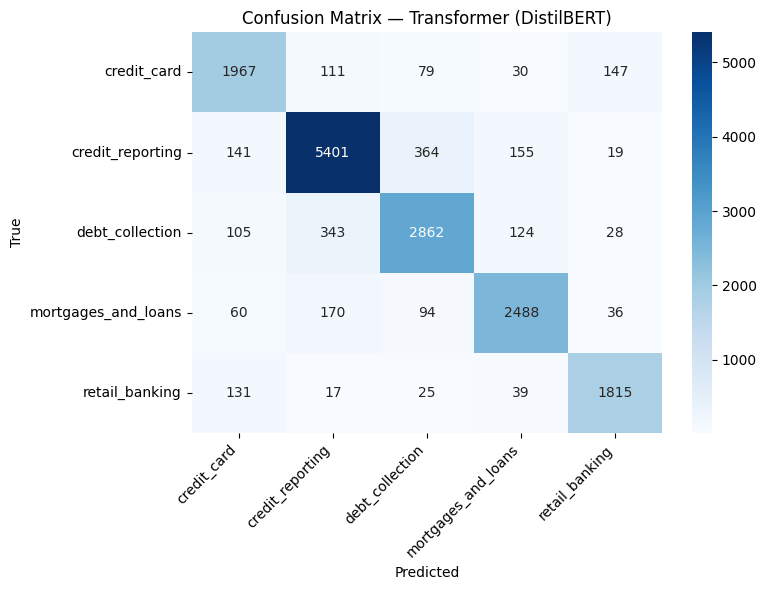

,Model,Accuracy,Precision,Recall,F1-score
0,Transformer (DistilBERT),0.867590,0.867770,0.867590,0.867643
1,GRU,0.846278,0.849886,0.846278,0.846672
2,LSTM,0.845442,0.850371,0.845442,0.846452
3,SimpleRNN,0.779595,0.790896,0.779595,0.781767


In [17]:
import seaborn as sns
from sklearn.metrics import (confusion_matrix, classification_report,
    accuracy_score, precision_recall_fscore_support)

classes = list(le.classes_)
results = []
all_preds = {}

def plot_cm(y_true, y_pred, model_name):
    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(8, 6))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=classes, yticklabels=classes)
    plt.title(f"Confusion Matrix — {model_name}")
    plt.ylabel("True"); plt.xlabel("Predicted")
    plt.xticks(rotation=45, ha="right"); plt.tight_layout(); plt.show()

# --- RNN family ---
for name, model in trained_models.items():
    probs = model.predict(X_test_pad, verbose=0)
    y_pred = np.argmax(probs, axis=1)
    all_preds[name] = y_pred
    acc = accuracy_score(y_test, y_pred)
    precision, recall, f1, _ = precision_recall_fscore_support(y_test, y_pred, average="weighted", zero_division=0)
    print(f"\n=== {name} ===")
    print(classification_report(y_test, y_pred, target_names=classes, zero_division=0))
    plot_cm(y_test, y_pred, name)
    results.append({"Model": name, "Accuracy": acc, "Precision": precision, "Recall": recall, "F1-score": f1})

# --- Transformer ---
device = "cuda" if torch.cuda.is_available() else "cpu"
transformer_model.to(device).eval()
preds = []
with torch.no_grad():
    for i in range(0, len(X_test), 32):
        batch = X_test[i:i+32]
        enc = hf_tokenizer(list(batch), truncation=True, padding=True, max_length=TRANSFORMER_MAX_LEN, return_tensors="pt").to(device)
        logits = transformer_model(**enc).logits
        preds.extend(torch.argmax(logits, dim=1).cpu().numpy())
y_pred_t = np.array(preds)
all_preds["Transformer (DistilBERT)"] = y_pred_t
acc = accuracy_score(y_test, y_pred_t)
precision, recall, f1, _ = precision_recall_fscore_support(y_test, y_pred_t, average="weighted", zero_division=0)
print("\n=== Transformer (DistilBERT) ===")
print(classification_report(y_test, y_pred_t, target_names=classes, zero_division=0))
plot_cm(y_test, y_pred_t, "Transformer (DistilBERT)")
results.append({"Model": "Transformer (DistilBERT)", "Accuracy": acc, "Precision": precision, "Recall": recall, "F1-score": f1})

comparison_df = pd.DataFrame(results).sort_values("F1-score", ascending=False).reset_index(drop=True)
comparison_df

/tmp/ipykernel_3985/1220635507.py:13: UserWarning: Glyph 127942 (\N{TROPHY}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 127942 (\N{TROPHY}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


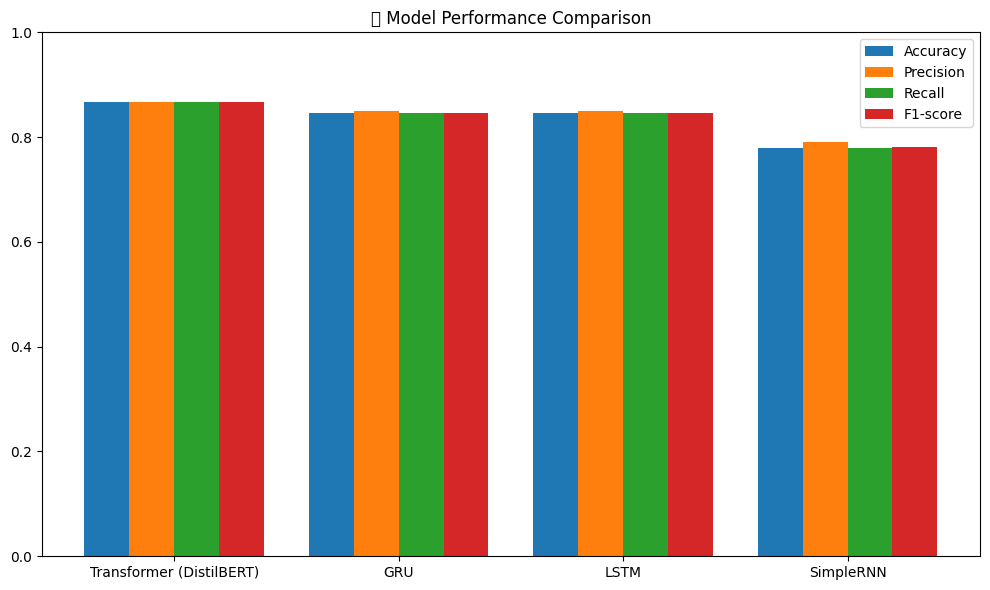

🥇 Best model: Transformer (DistilBERT)


In [18]:
# Final comparison chart
metrics = ["Accuracy", "Precision", "Recall", "F1-score"]
fig, ax = plt.subplots(figsize=(10, 6))
x = np.arange(len(comparison_df))
width = 0.2
for i, metric in enumerate(metrics):
    ax.bar(x + i*width, comparison_df[metric], width, label=metric)
ax.set_xticks(x + width*1.5)
ax.set_xticklabels(comparison_df["Model"])
ax.set_ylim(0, 1)
ax.set_title("🏆 Model Performance Comparison")
ax.legend()
plt.tight_layout()
plt.show()

best_model_name = comparison_df.iloc[0]["Model"]
print(f"🥇 Best model: {best_model_name}")

### 🔬 Extra analysis: baseline, final comparison and error analysis

In [19]:
# A) Classical baseline: TF-IDF + Logistic Regression (shows what deep learning actually adds)
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

tfidf = TfidfVectorizer(max_features=50000, ngram_range=(1, 2), sublinear_tf=True)
Xtr_tfidf = tfidf.fit_transform(X_train)      # fit on the training split only (no leakage)
Xte_tfidf = tfidf.transform(X_test)

baseline = LogisticRegression(max_iter=1000, class_weight="balanced")
baseline.fit(Xtr_tfidf, y_train)
y_pred_base = baseline.predict(Xte_tfidf)
all_preds["TF-IDF + LogReg (baseline)"] = y_pred_base

print(classification_report(y_test, y_pred_base, target_names=classes, zero_division=0))

                     precision    recall  f1-score   support

        credit_card       0.79      0.85      0.82      2334
   credit_reporting       0.91      0.84      0.88      6080
    debt_collection       0.83      0.84      0.83      3462
mortgages_and_loans       0.85      0.89      0.87      2848
     retail_banking       0.86      0.90      0.88      2027

           accuracy                           0.86     16751
          macro avg       0.85      0.87      0.86     16751
       weighted avg       0.86      0.86      0.86     16751



In [20]:
# B) Final comparison table (Macro F1 is the primary metric because the classes are not equally sized)
from sklearn.metrics import f1_score, precision_score, recall_score

rows = []
for name, yp in all_preds.items():
    rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, yp),
        "Macro Precision": precision_score(y_test, yp, average="macro", zero_division=0),
        "Macro Recall": recall_score(y_test, yp, average="macro", zero_division=0),
        "Macro F1": f1_score(y_test, yp, average="macro", zero_division=0),
        "Weighted F1": f1_score(y_test, yp, average="weighted", zero_division=0),
    })

final_df = pd.DataFrame(rows).sort_values("Macro F1", ascending=False).reset_index(drop=True)
os.makedirs("outputs", exist_ok=True)
final_df.to_csv("outputs/final_comparison.csv", index=False)
best_model_name = final_df.iloc[0]["Model"]
print(f"Test set size: {len(y_test)}")
print(f"🥇 Best by Macro F1: {best_model_name}")
final_df.round(4)

Test set size: 16751
🥇 Best by Macro F1: Transformer (DistilBERT)


,Model,Accuracy,Macro Precision,Macro Recall,Macro F1,Weighted F1
0,Transformer (DistilBERT),0.8676,0.8626,0.8654,0.8639,0.8676
1,TF-IDF + LogReg (baseline),0.8580,0.8474,0.8652,0.8555,0.8584
2,GRU,0.8463,0.8330,0.8554,0.8429,0.8467
3,LSTM,0.8454,0.8325,0.8515,0.8406,0.8465
4,SimpleRNN,0.7796,0.7639,0.7835,0.7706,0.7818


In [21]:
# C) Error analysis for the best model: top confusions + 10 misclassified examples
best_pred = all_preds[best_model_name]
cm = confusion_matrix(y_test, best_pred)

pairs = [(classes[i], classes[j], int(cm[i, j]))
         for i in range(len(classes)) for j in range(len(classes)) if i != j and cm[i, j] > 0]
pairs.sort(key=lambda t: -t[2])
confusions_df = pd.DataFrame(pairs[:10], columns=["True class", "Predicted as", "Count"])
print(f"Top confusions for: {best_model_name}")
display(confusions_df)

wrong_idx = np.where(best_pred != y_test)[0]
print(f"Wrong predictions: {len(wrong_idx)} / {len(y_test)}")
rng = np.random.RandomState(42)
sample_idx = rng.choice(wrong_idx, size=min(10, len(wrong_idx)), replace=False)
errors_df = pd.DataFrame({
    "text (cleaned)": [X_test[i][:250] for i in sample_idx],
    "true": [classes[y_test[i]] for i in sample_idx],
    "predicted": [classes[best_pred[i]] for i in sample_idx],
})
errors_df.to_csv("outputs/error_examples.csv", index=False)
confusions_df.to_csv("outputs/top_confusions.csv", index=False)
pd.set_option("display.max_colwidth", 250)
errors_df

Top confusions for: Transformer (DistilBERT)


,True class,Predicted as,Count
0,credit_reporting,debt_collection,364
1,debt_collection,credit_reporting,343
2,mortgages_and_loans,credit_reporting,170
3,credit_reporting,mortgages_and_loans,155
4,credit_card,retail_banking,147
5,credit_reporting,credit_card,141
6,retail_banking,credit_card,131
7,debt_collection,mortgages_and_loans,124
8,credit_card,credit_reporting,111
9,debt_collection,credit_card,105


Wrong predictions: 2218 / 16751


,text (cleaned),true,predicted
0,changed bank america credit card account autopay told insufficient time autopay cover next payment unbeknownst next payment delinquent reported three four call company asking corrected credit report avail late payment several year,credit_reporting,credit_card
1,obligation reporting equifax credit report account violation fcra multiple inaccuracy open date incorrect date last active incorrect date last payment incorrect monthly payment reflecting incorrect ruining debt income ratio account reporting like...,debt_collection,credit_reporting
2,shocked reviewed credit report week found multiple inaccuracy credit report major credit bureau collection company never dealt attempted several time ratify issue original creditor credit bureau still reporting inaccurate unverifiable information...,credit_reporting,debt_collection
3,contacted loanme opportunity defer next payment due signed agreement completed requirement received confirmation agreement accepted reviewing credit report see loanme currently reporting account day past due although loanme owned loan since loanm...,mortgages_and_loans,credit_reporting
4,company open account rental agreement amount paid account full company never reported credit bureau demand account updated paid full,mortgages_and_loans,credit_reporting
5,attempting early access loan future direct deposit fifth third bank took amount borrowed checking account applied credit card claimed back never received paperwork regarding account fact remember account back year ago supposedly number account en...,retail_banking,debt_collection
6,notified account closed notified hsn credit card account transferred transfer balance almost doubled never received new card letter notify transfer dictated find account closed several month transferred even though balance owed incorrect tried se...,debt_collection,credit_reporting
7,radius global solution llc trying collect loan statute limitation creditor listed formerly known statue limitation loan expired would like never contacted loan ever removed system including system formerly known called radius global solution gave...,mortgages_and_loans,debt_collection
8,disputing account number paying month year continues state credit report charge amount owned never change well example closed example transunion last reported reported balance remark charged bad debt profit loss transunion please remove credit re...,debt_collection,credit_reporting
9,provided bank america debit card cash pay short term work period able withdraw since unable withdraw remaining tried several bank america atm even spoke bank america representative success told contact government agency card end social security n...,retail_banking,credit_card


## 1️⃣1️⃣ Classify new complaints with the best model

In [24]:
import joblib
os.makedirs("models", exist_ok=True)
joblib.dump(tokenizer, "models/tokenizer.pkl")
joblib.dump(le, "models/label_encoder.pkl")
with open("models/config.json", "w") as f:
    json.dump({"max_vocab_size": MAX_VOCAB_SIZE, "max_seq_len": MAX_SEQ_LEN,
               "num_classes": num_classes, "classes": classes}, f, indent=2)

def predict_new_complaint(text, model_name="LSTM", top_k=3):
    cleaned = clean_text(text)
    device = "cuda" if torch.cuda.is_available() else "cpu"
    
    if model_name == "Transformer (DistilBERT)":
        # Ensure model is on the correct device
        transformer_model.to(device)
        # Move encoded tensors to the same device (GPU/CPU) as the model
        enc = hf_tokenizer(cleaned, truncation=True, padding=True, max_length=TRANSFORMER_MAX_LEN, return_tensors="pt").to(device)
        with torch.no_grad():
            logits = transformer_model(**enc).logits
            # Move tensor back to CPU before converting to numpy
            probs = torch.softmax(logits, dim=1).squeeze().cpu().numpy()
    else:
        seq = tokenizer.texts_to_sequences([cleaned])
        padded = pad_sequences(seq, maxlen=MAX_SEQ_LEN, padding="post", truncating="post")
        probs = trained_models[model_name].predict(padded, verbose=0)[0]
        
    top_idx = np.argsort(probs)[::-1][:top_k]
    return [(classes[i], float(probs[i])) for i in top_idx]

sample_complaint = "I have been charged an overdraft fee multiple times even though I always kept enough balance in my account."
demo_model = best_model_name if (best_model_name in trained_models or best_model_name == "Transformer (DistilBERT)") else "LSTM"
print("Model used for demo:", demo_model)
for r in predict_new_complaint(sample_complaint, model_name=demo_model):
    print(f"{r[0]:35s} -> {r[1]*100:.2f}%")

Model used for demo: Transformer (DistilBERT)
retail_banking                      -> 91.56%
mortgages_and_loans                 -> 3.84%
credit_card                         -> 3.19%


## 1️⃣2️⃣ Deploy with Gradio

This cell builds and launches the interactive Gradio app directly inside the notebook (with a public link when `share=True`).

In [25]:
import inspect
import gradio as gr

EXAMPLES = [
    ["I was charged twice for the same purchase on my credit card and the bank refuses to refund me."],
    ["My mortgage servicer started foreclosure even though I have been making my payments on time."],
    ["A debt collector keeps calling me multiple times a day about a debt that isn't even mine."],
]
available_models = list(trained_models.keys()) + (["Transformer (DistilBERT)"] if "transformer_model" in dir() else [])

CUSTOM_CSS = """
.gradio-container { font-family: 'Segoe UI', 'Inter', sans-serif !important;
    background: linear-gradient(135deg, #0f172a 0%, #1e293b 100%) !important; }
#header h1 { font-size: 2.1rem; background: linear-gradient(90deg, #60a5fa, #a78bfa);
    -webkit-background-clip: text; -webkit-text-fill-color: transparent; font-weight: 800; }
#predict-btn { background: linear-gradient(90deg, #2563eb, #7c3aed) !important; color: white !important;
    font-weight: 700 !important; border: none !important; border-radius: 12px !important; }
footer {visibility: hidden}
"""

THEME = gr.themes.Soft(primary_hue="blue", secondary_hue="violet", neutral_hue="slate")

def plot_top_k(top_results):
    labels = [r[0] for r in top_results][::-1]
    scores = [r[1]*100 for r in top_results][::-1]
    fig, ax = plt.subplots(figsize=(6, 3))
    fig.patch.set_alpha(0); ax.set_facecolor("none")
    bars = ax.barh(labels, scores, color=plt.cm.Blues([0.9-0.2*i for i in range(len(scores))]))
    for bar, score in zip(bars, scores):
        ax.text(bar.get_width()+1.5, bar.get_y()+bar.get_height()/2, f"{score:.1f}%", va="center", fontsize=10)
    ax.set_xlim(0, 105); ax.set_title("Top Predictions")
    plt.tight_layout()
    return fig

def classify_complaint(text, model_name):
    if not text or not text.strip():
        return "⚠️ Please enter the complaint text", "", None
    try:
        top_results = predict_new_complaint(text, model_name=model_name, top_k=3)
    except Exception as e:
        return f"❌ Could not run model {model_name}: {type(e).__name__}: {e}", "", None
    label, confidence = top_results[0]
    result_html = (
        "<div style='padding:14px;border-radius:12px;background:rgba(37,99,235,0.12);'>"
        "<div style='color:#93c5fd;'>Predicted category</div>"
        f"<div style='color:#f8fafc;font-size:1.5rem;font-weight:800;'>{label}</div></div>"
    )
    confidence_html = (
        "<div style='margin-top:10px;text-align:center;color:#34d399;font-weight:700;'>"
        f"✅ Confidence score: {confidence*100:.2f}%</div>"
    )
    return result_html, confidence_html, plot_top_k(top_results)

# Gradio >= 6 expects theme/css in launch(); older versions expect them in gr.Blocks()
_NEW_GRADIO_API = "theme" in inspect.signature(gr.Blocks.launch).parameters
_blocks_kwargs = {} if _NEW_GRADIO_API else {"theme": THEME, "css": CUSTOM_CSS}
_launch_kwargs = {"theme": THEME, "css": CUSTOM_CSS} if _NEW_GRADIO_API else {}

with gr.Blocks(title="Consumer Complaint Classifier", **_blocks_kwargs) as demo:
    with gr.Column(elem_id="header"):
        gr.Markdown("# 🏦 Consumer Complaint Classifier")
        gr.Markdown("Automatically routes customer complaints to the right product category")
    with gr.Row():
        with gr.Column():
            complaint_input = gr.Textbox(label="Complaint narrative", lines=8, placeholder="Type or paste the customer complaint here...")
            model_choice = gr.Radio(choices=available_models, value=available_models[0], label="🧠 Choose a model")
            predict_btn = gr.Button("🔍 Classify Complaint", elem_id="predict-btn")
            gr.Examples(examples=EXAMPLES, inputs=[complaint_input])
        with gr.Column():
            result_output = gr.HTML()
            confidence_output = gr.HTML()
            chart_output = gr.Plot()
    predict_btn.click(classify_complaint, [complaint_input, model_choice], [result_output, confidence_output, chart_output])

demo.launch(share=True, **_launch_kwargs)  # share=True creates a public link you can open from anywhere

* Running on local URL:  http://127.0.0.1:7861
* Running on public URL: https://1e77a549b8592166a8.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [28]:
   import json, sys, importlib
   v = {"python": sys.version.split()[0]}
   for k, m in [("tensorflow","tensorflow"),("keras","keras"),("scikit-learn","sklearn"),("torch","torch"),("transformers","transformers")]:
       v[k] = importlib.import_module(m).__version__
   json.dump(v, open("models/versions.json", "w"), indent=2)